<a href="https://colab.research.google.com/github/manueljesusmatus/Tarea-3-ANN/blob/master/Tarea3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
 
from tensorflow import keras
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import NearestNeighbors 
from keras.utils.vis_utils import plot_model
import numpy as np
from matplotlib import pyplot as plt
 
import cv2
import os
import pickle
import random
import collections
 
from scipy import spatial
from keras.models import Sequential, Model
from keras.layers import Dense,InputLayer,Input,Dropout
from keras.layers import Conv2D,Flatten,Reshape,MaxPool2D,UpSampling2D,MaxPooling2D,Conv2DTranspose,LeakyReLU,BatchNormalization,Activation
 
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score, multilabel_confusion_matrix

#Tarea 3 Grupo SQILLS
## Integrantes:
+ Vicente Manriquez
+ Manuel Matus
+ Matias Guzman 

## PARTE 1 


# Inter-domain Image2Image

## Load Dataset

In [ ]:
from keras.datasets import cifar10
import keras
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

170500096/170498071 [==============================] - 11s 0us/step


In [ ]:
X_train = X_train.astype('float32') / 255.
X_test = X_test.astype('float32') / 255.

X_train = X_train.reshape(-1,32,32,3)
X_test = X_test.reshape(-1,32,32,3)

#one hot 
y_train_HE = keras.utils.to_categorical(y_train)
y_test_HE = keras.utils.to_categorical(y_test)

<class 'numpy.ndarray'>


In [ ]:
INPUT_SHAPE = (32,32,3)
DIM_ENCOD = 500 #16%
EPOCHS = 15
BATCH_SIZE = 128
NAMES = ['Airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
THRESHOLD = 10

## AE -> Euclidean distance

### Red

In [ ]:
def Red(dim_encod,shape):
  input_img = Input(shape=shape)
  chanDim = -1

  # Encoder Layers
  x = Conv2D(32, (3, 3), activation = LeakyReLU(alpha=0.2), padding="same")(input_img)
  x = Conv2D(32, (3, 3), activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = MaxPooling2D((2, 2), padding='same')(x)
  x = Dropout(0.2)(x)
  x = Conv2D(64, (3, 3), activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = Conv2D(64, (3, 3), activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = MaxPooling2D((2, 2), padding='same')(x)
  x = Dropout(0.2)(x)
  x = Flatten()(x)
  encoded = Dense(dim_encod, name="embedding")(x)


  # Decoder Layers
  flat_layer = Dense(4*4*128)(encoded)
  x = Reshape((4,4,128))(flat_layer)
  x = Conv2DTranspose(128, (3, 3), strides=2, activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = Conv2DTranspose(64, (3, 3), strides=2, activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = Conv2DTranspose(32, (3, 3), strides=2, activation = LeakyReLU(alpha=0.2), padding="same")(x)
  decoded = Conv2DTranspose(3, (3, 3), padding="same", activation = 'sigmoid', name="decoded")(x)


  # Models
  autoencoder = Model(input_img, decoded)
  encoder = Model(input_img, encoded)
  autoencoder.compile(optimizer='adam', loss='mse')
  return autoencoder, encoder
AE_1, E_1 = Red(DIM_ENCOD,INPUT_SHAPE)

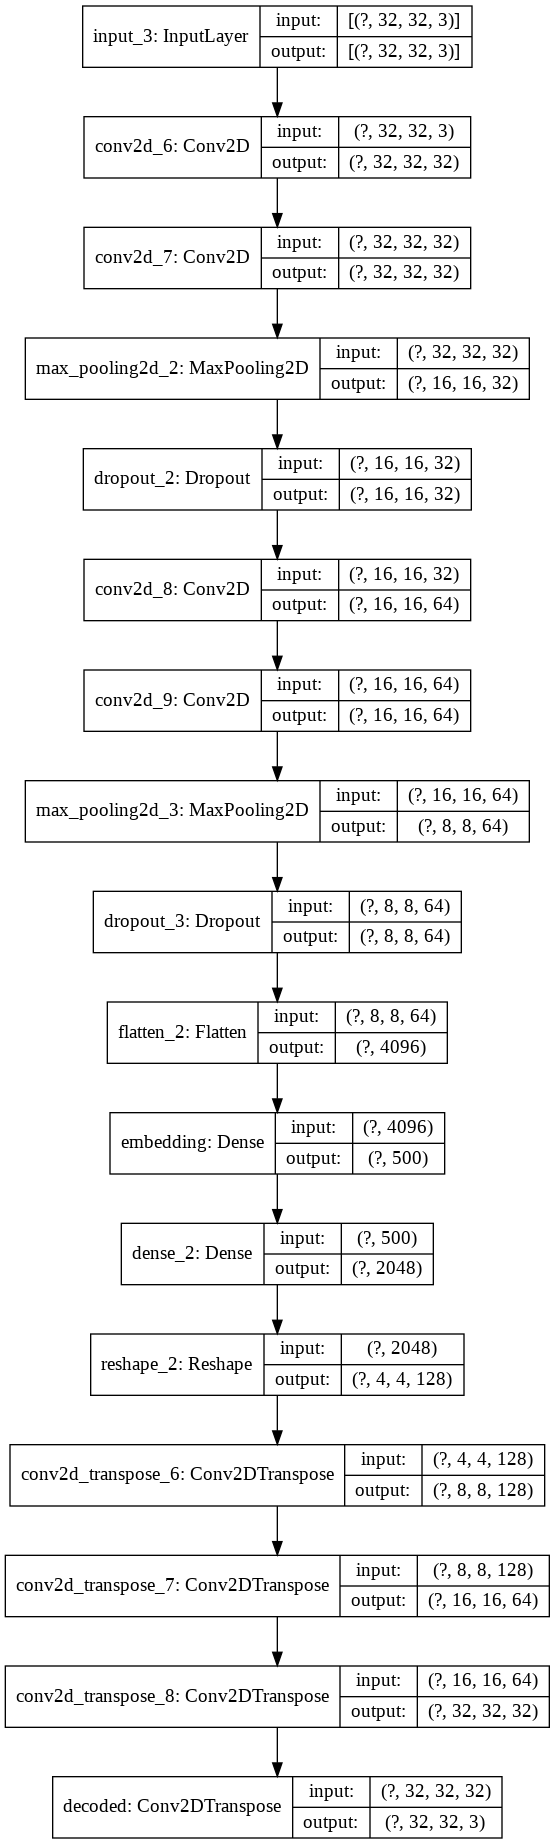

In [ ]:
AE_1, E_1 = Red(DIM_ENCOD,INPUT_SHAPE)
plot_model(AE_1, show_shapes=True, show_layer_names=True)

In [ ]:
history_AE_1 = AE_1.fit(X_train, X_train, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_split=0.2)

Epoch 1/15
313/313 [==============================] - 17s 55ms/step - loss: 0.0214 - val_loss: 0.0111
Epoch 2/15
313/313 [==============================] - 16s 53ms/step - loss: 0.0088 - val_loss: 0.0073
Epoch 3/15
313/313 [==============================] - 17s 54ms/step - loss: 0.0071 - val_loss: 0.0058
Epoch 4/15
313/313 [==============================] - 17s 53ms/step - loss: 0.0059 - val_loss: 0.0050
Epoch 5/15
313/313 [==============================] - 17s 54ms/step - loss: 0.0054 - val_loss: 0.0048
Epoch 6/15
313/313 [==============================] - 17s 53ms/step - loss: 0.0050 - val_loss: 0.0042
Epoch 7/15
313/313 [==============================] - 17s 53ms/step - loss: 0.0047 - val_loss: 0.0042
Epoch 8/15
313/313 [==============================] - 17s 53ms/step - loss: 0.0045 - val_loss: 0.0039
Epoch 9/15
313/313 [==============================] - 16s 53ms/step - loss: 0.0043 - val_loss: 0.0037
Epoch 10/15
313/313 [==============================] - 16s 52ms/step - loss: 0.004

### Resultados

In [ ]:
X_decoded_train = AE_1.predict(X_train)
X_decoded_test = AE_1.predict(X_test)

Z_embedding_train = E_1.predict(X_train)
Z_embedding_test = E_1.predict(X_test)

Text(0.5, 1.0, 'Decoded image')

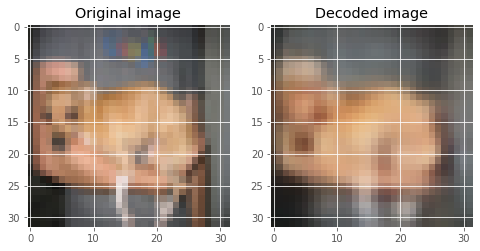

In [ ]:
fig=plt.figure(figsize=(8, 8))

_img = random.randint(0,X_test.shape[0])

ax = fig.add_subplot(1, 2, 1)
imgplot = plt.imshow(X_test[_img])
ax.set_title('Original image')

ax = fig.add_subplot(1, 2, 2)
imgplot = plt.imshow(X_decoded_test[_img])
ax.set_title('Decoded image')

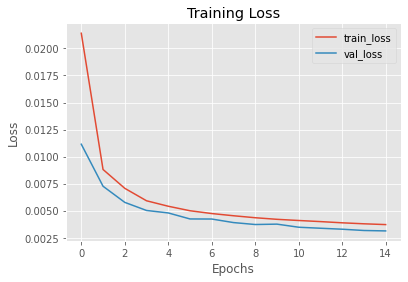

In [ ]:
N = np.arange(0, EPOCHS)
plt.style.use("ggplot")
plt.figure()
plt.plot(N, history_AE_1.history["loss"], label="train_loss")
plt.plot(N, history_AE_1.history["val_loss"], label="val_loss")
plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(loc="upper right")

### Modelo

In [ ]:
indexes = list(range(0, X_train.shape[0]))
DataBase = {"indexes": indexes, "features": Z_embedding_train}

In [ ]:
def DBsearch(queryImg, index, maxResults=64):
	results = []
	for i in range(0, len(index["features"])):
		d = euclidean(queryImg, index["features"][i])
		results.append((d, i))
	results = sorted(results)[:maxResults]
	return results

def euclidean(a, b):
	# compute and return the euclidean distance between two vectors
	return np.linalg.norm(a - b)

In [ ]:
N_QUERIES = 5
queries_imgs =  random.sample(range(Z_embedding_test.shape[0]), N_QUERIES)
result_queries = [ DBsearch(Z_embedding_test[i], DataBase, THRESHOLD) for i in queries_imgs]

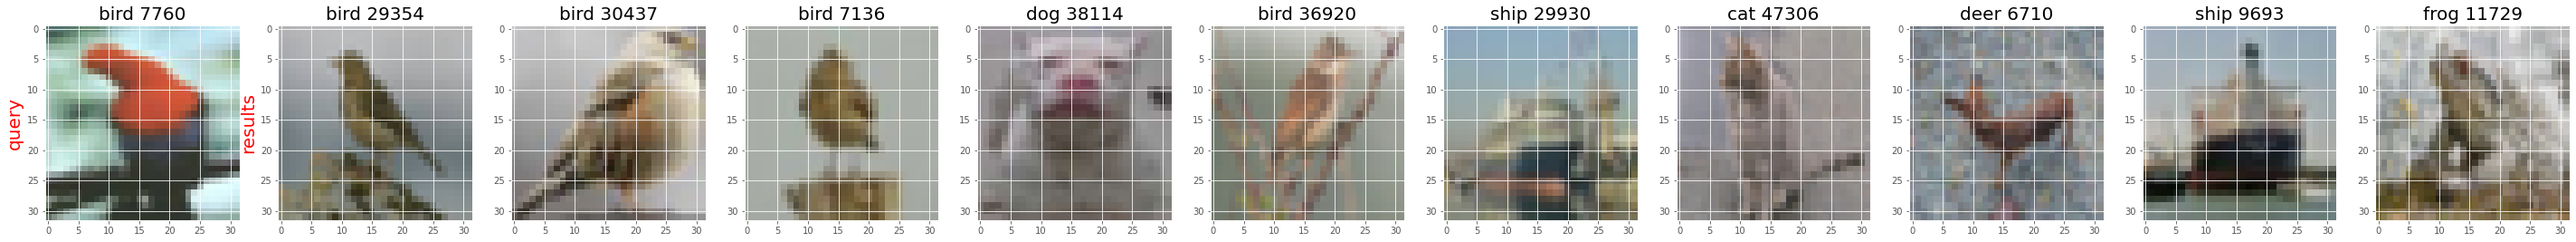

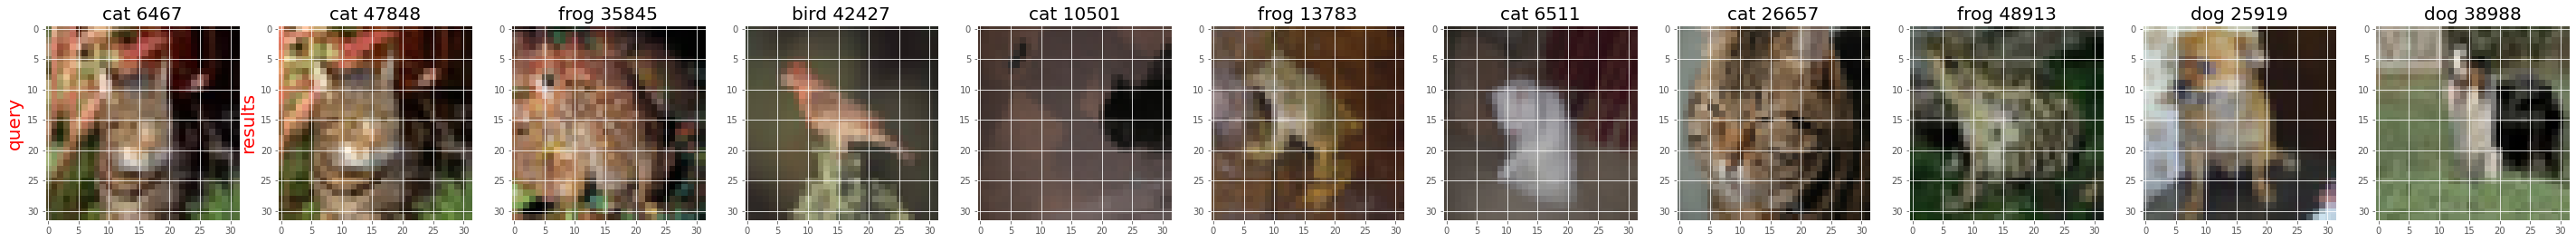

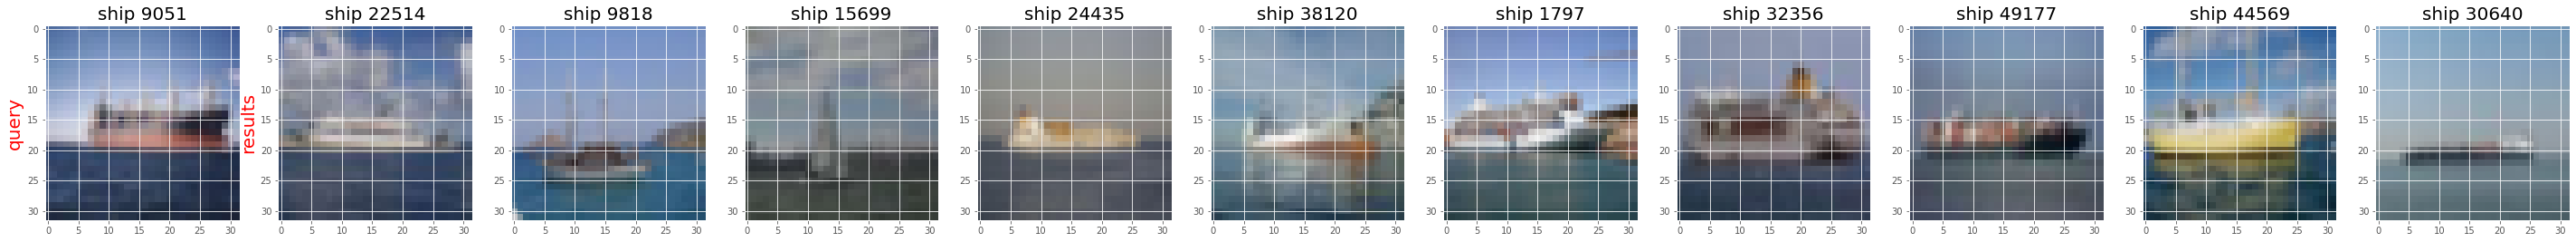

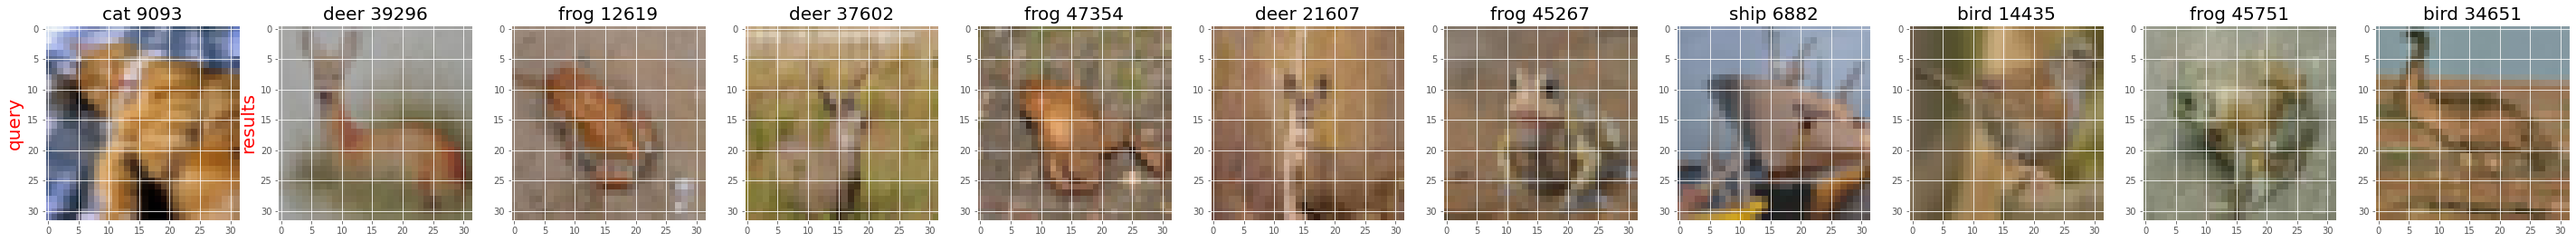

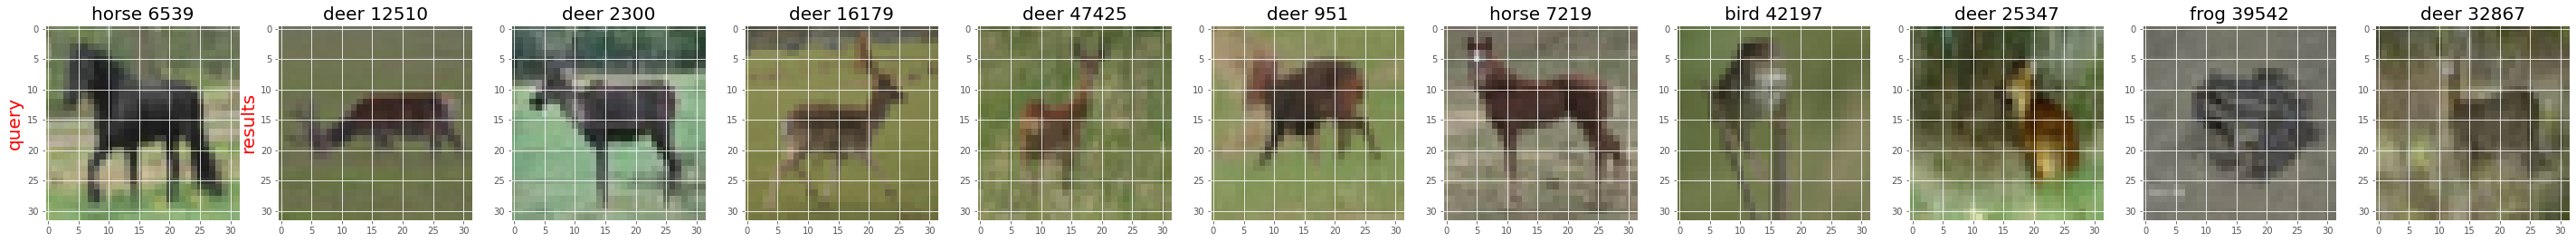

In [ ]:
for i in range(N_QUERIES):
  res = result_queries[i]
  _img = queries_imgs[i]
  N = len(res)

  fig=plt.figure(figsize=(50, 32))
  ax = fig.add_subplot(1, N+1, 1)
  plt.imshow(X_test[_img])
  ax.set_ylabel('query',fontsize=20, color='r')
  plt.title(f'{NAMES[y_test[_img][0]]} {_img}',fontsize=20)
  for i in range(N):
    _index = res[i][1]
    ax = fig.add_subplot(1, N+1, i+2)
    imgplot = plt.imshow(X_train[_index])
    ax.set_title(f'{NAMES[y_train[_index][0]]} {_index}',fontsize=20)
    if(i==0):
      ax.set_ylabel('results',fontsize=20, color='r')

#### Métrica

In [ ]:
def CountRelevantDocuments( results, y_label ):
  rd = 0
  for i in results:
    if( y_train[i[1]] == y_label):
      rd+=1
  return rd

def _precision_at_k(indexes, Z_embedding, DataBase, k=10):
  #N = Z_embedding.shape[0]
  N = len(indexes)
  total = 0
  for i in range(N):
    res = DBsearch(Z_embedding[i], DataBase, k) 
    relevants = CountRelevantDocuments(res,y_test[i][0])
    total += (relevants/k)
  return total/N

In [ ]:
indexes =  random.sample(range(Z_embedding_test.shape[0]), 1000)
_precision_at_k(indexes, Z_embedding_test, DataBase)

0.26789999999999925

In [ ]:
indexes =  random.sample(range(Z_embedding_test.shape[0]), 100)
_precision_at_k(indexes, Z_embedding_test, DataBase)

0.275

## AE + KNN-> Euclidian distance

### Red

In [ ]:
def Red(dim_encod,shape):
  input_img = Input(shape=shape)
  chanDim = -1

  # Encoder Layers
  x = Conv2D(32, (3, 3), activation = LeakyReLU(alpha=0.2), padding="same")(input_img)
  x = Conv2D(32, (3, 3), activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = MaxPooling2D((2, 2), padding='same')(x)
  x = Dropout(0.2)(x)
  x = Conv2D(64, (3, 3), activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = Conv2D(64, (3, 3), activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = MaxPooling2D((2, 2), padding='same')(x)
  x = Dropout(0.2)(x)
  x = Flatten()(x)
  encoded = Dense(dim_encod, name="embedding")(x)


  # Decoder Layers
  flat_layer = Dense(4*4*128)(encoded)
  x = Reshape((4,4,128))(flat_layer)
  x = Conv2DTranspose(128, (3, 3), strides=2, activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = Conv2DTranspose(64, (3, 3), strides=2, activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = Conv2DTranspose(32, (3, 3), strides=2, activation = LeakyReLU(alpha=0.2), padding="same")(x)
  decoded = Conv2DTranspose(3, (3, 3), padding="same", activation = 'sigmoid', name="decoded")(x)


  # Models
  autoencoder = Model(input_img, decoded)
  encoder = Model(input_img, encoded)
  autoencoder.compile(optimizer='adam', loss='mse')
  return autoencoder, encoder
AE_2, E_2 = Red(DIM_ENCOD,INPUT_SHAPE)

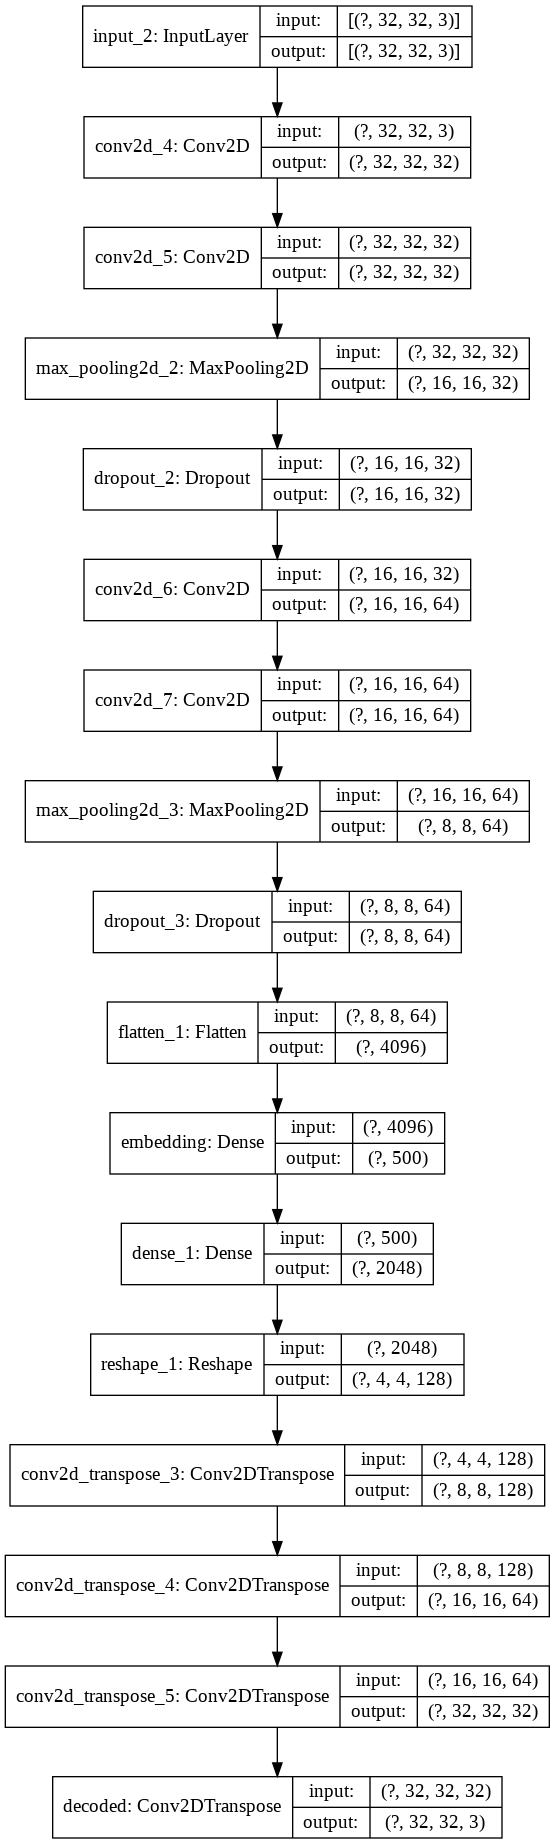

In [ ]:
AE_2, E_2 = Red(DIM_ENCOD,INPUT_SHAPE)
plot_model(AE_2, show_shapes=True, show_layer_names=True)

In [ ]:
history_AE_2 = AE_2.fit(X_train, X_train, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_split=0.2)

Epoch 1/15
313/313 [==============================] - 8s 25ms/step - loss: 0.0209 - val_loss: 0.0102
Epoch 2/15
313/313 [==============================] - 7s 24ms/step - loss: 0.0085 - val_loss: 0.0068
Epoch 3/15
313/313 [==============================] - 8s 24ms/step - loss: 0.0067 - val_loss: 0.0056
Epoch 4/15
313/313 [==============================] - 8s 24ms/step - loss: 0.0058 - val_loss: 0.0051
Epoch 5/15
313/313 [==============================] - 8s 24ms/step - loss: 0.0053 - val_loss: 0.0047
Epoch 6/15
313/313 [==============================] - 8s 24ms/step - loss: 0.0050 - val_loss: 0.0042
Epoch 7/15
313/313 [==============================] - 8s 25ms/step - loss: 0.0047 - val_loss: 0.0041
Epoch 8/15
313/313 [==============================] - 8s 25ms/step - loss: 0.0045 - val_loss: 0.0038
Epoch 9/15
313/313 [==============================] - 8s 25ms/step - loss: 0.0043 - val_loss: 0.0037
Epoch 10/15
313/313 [==============================] - 8s 25ms/step - loss: 0.0042 - val_lo

### Predict

In [ ]:
X_decoded_train = AE_2.predict(X_train)
X_decoded_test = AE_2.predict(X_test)

Z_embedding_train = E_2.predict(X_train)
Z_embedding_test = E_2.predict(X_test)

Text(0.5, 1.0, 'Decoded image')

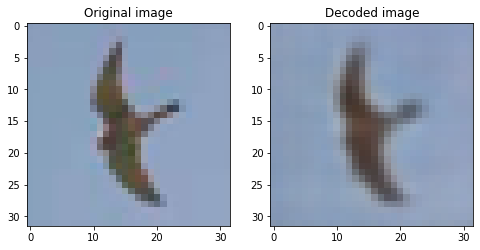

In [ ]:
fig=plt.figure(figsize=(8, 8))

_img = random.randint(0,X_test.shape[0])

ax = fig.add_subplot(1, 2, 1)
imgplot = plt.imshow(X_test[_img])
ax.set_title('Original image')

ax = fig.add_subplot(1, 2, 2)
imgplot = plt.imshow(X_decoded_test[_img])
ax.set_title('Decoded image')

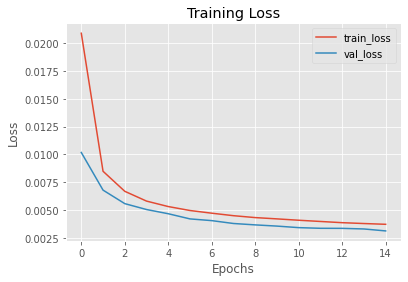

In [ ]:
N = np.arange(0, EPOCHS)
plt.style.use("ggplot")
plt.figure()
plt.plot(N, history_AE_2.history["loss"], label="train_loss")
plt.plot(N, history_AE_2.history["val_loss"], label="val_loss")
plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(loc="upper right")

In [ ]:
knn = KNeighborsClassifier(n_neighbors= THRESHOLD)

In [ ]:
knn.fit(Z_embedding_train, y_train)

/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:1: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  """Entry point for launching an IPython kernel.


KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
                     metric_params=None, n_jobs=None, n_neighbors=10, p=2,
                     weights='uniform')

### Modelo 1 KNNpredict

In [ ]:
def SetDictionary(Z_embedding,y_labels):
  n = y_labels.shape[0]
  d = {}
  for i in range(n):
    try:
      d[y_labels[i][0]].append((i,Z_embedding[i]))
    except:
      d[y_labels[i][0]] = [(i,Z_embedding[i])]
  return d

def DBsearch_2(queryImg, label_predict, index, maxResults=64):
	results = []
	for i in range( len(index[ label_predict ]) ):
		d = euclidean(queryImg, index[ label_predict ][i][1])
		results.append((d, index[ label_predict ][i][0]))
	results = sorted(results)[:maxResults]
	return results

def euclidean(a, b):
	# compute and return the euclidean distance between two vectors
	return np.linalg.norm(a - b)

In [ ]:
DataBase = SetDictionary(Z_embedding_train,y_train)

In [ ]:
N_QUERIES = 5
queries_imgs =  random.sample(range(Z_embedding_test.shape[0]), N_QUERIES)
result_queries = [ DBsearch_2(Z_embedding_test[i], knn.predict([Z_embedding_test[i]])[0], DataBase, THRESHOLD) for i in queries_imgs]

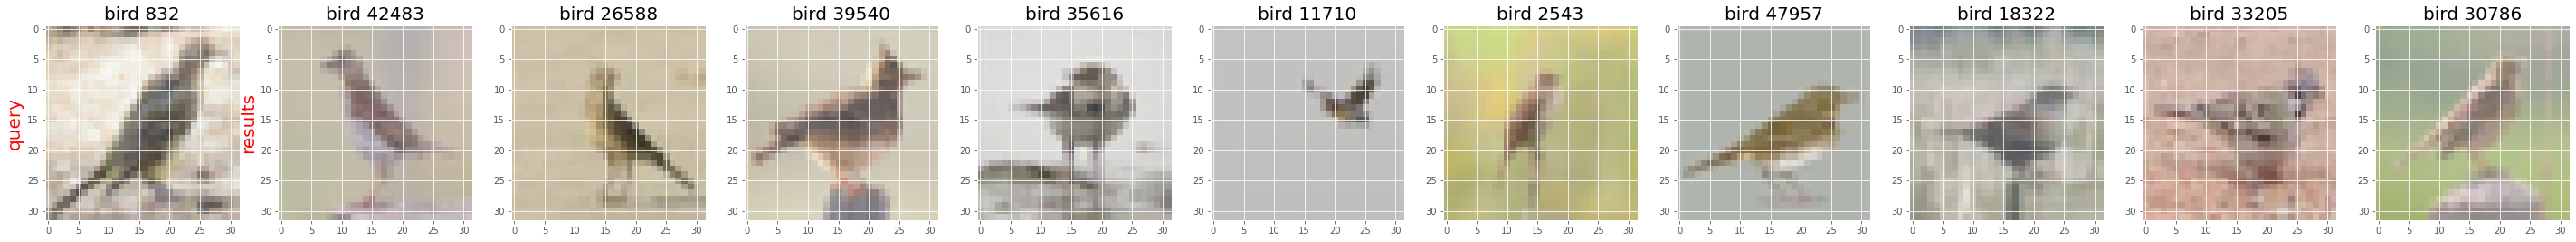

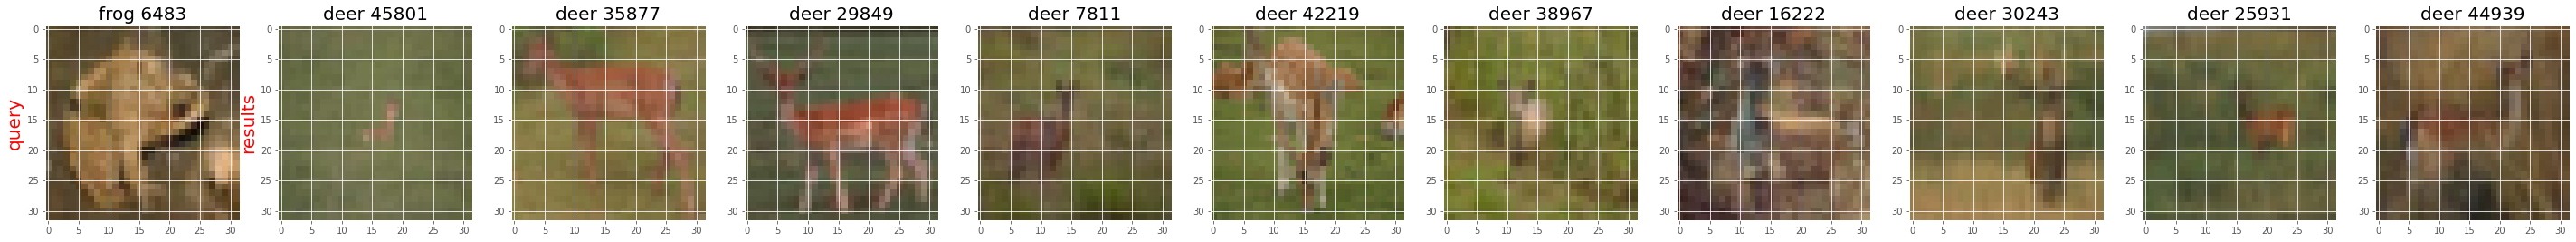

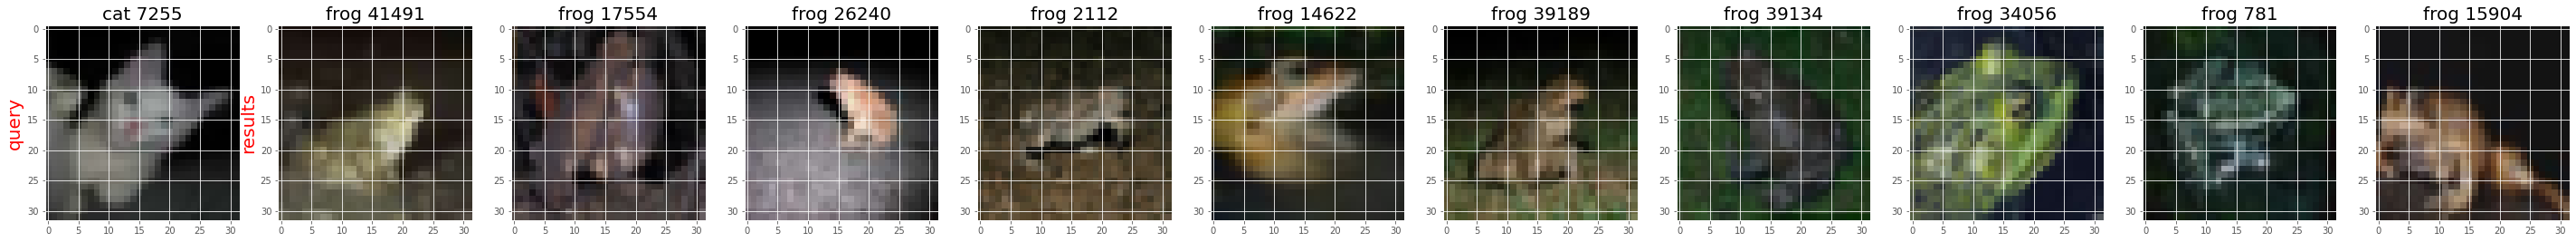

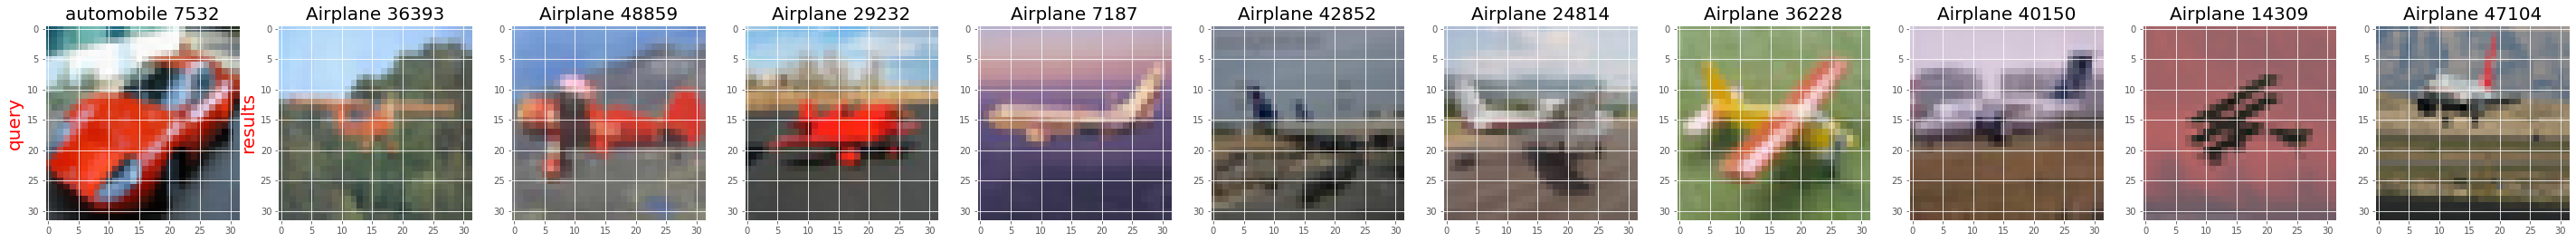

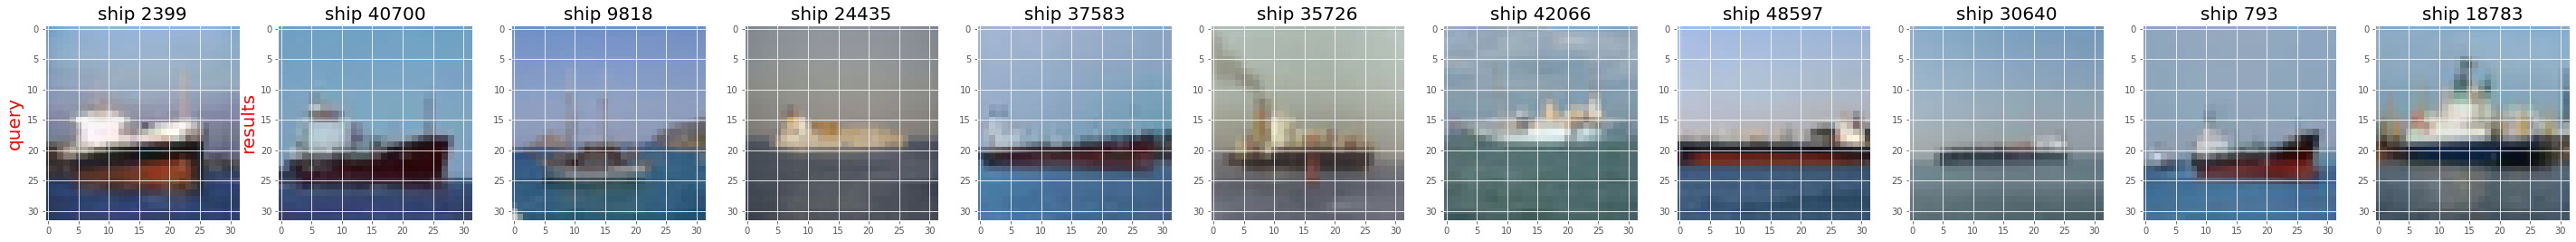

In [ ]:
for i in range(N_QUERIES):
  res = result_queries[i]
  _img = queries_imgs[i]
  N = len(res)

  fig=plt.figure(figsize=(50, 32))
  ax = fig.add_subplot(1, N+1, 1)
  plt.imshow(X_test[_img])
  ax.set_ylabel('query',fontsize=20, color='r')
  plt.title(f'{NAMES[y_test[_img][0]]} {_img}',fontsize=20)
  for i in range(N):
    _index = res[i][1]
    ax = fig.add_subplot(1, N+1, i+2)
    imgplot = plt.imshow(X_train[_index])
    ax.set_title(f'{NAMES[y_train[_index][0]]} {_index}',fontsize=20)
    if(i==0):
      ax.set_ylabel('results',fontsize=20, color='r')

#### Métricas

In [ ]:
def CountRelevantDocuments( results, y_label ):
  rd = 0
  for i in results:
    if( y_train[i[1]] == y_label):
      rd+=1
  return rd

def _precision_at_k(Z_embedding, DataBase, k=10):
  N = Z_embedding.shape[0]
  total = 0
  for i in range(N):
    res = DBsearch_2(Z_embedding_test[i], knn.predict([Z_embedding_test[i]])[0], DataBase, THRESHOLD)
    relevants = CountRelevantDocuments(res,y_test[i][0])
    total += (relevants/k)
  return total/N

In [ ]:
_precision_at_k(Z_embedding_test, DataBase)

0.325

### Modelo 2 KNNeighbors

In [ ]:
N_QUERIES = 5
queries_imgs =  random.sample(range(Z_embedding_test.shape[0]), N_QUERIES)
result_queries = [ knn.kneighbors([Z_embedding_test[i]])[1][0] for i in queries_imgs]

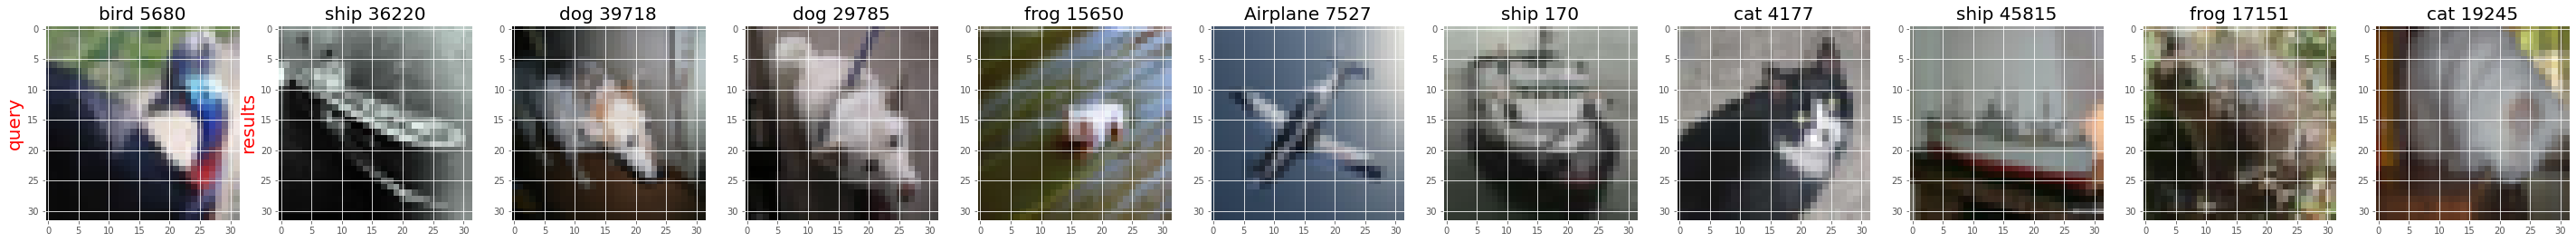

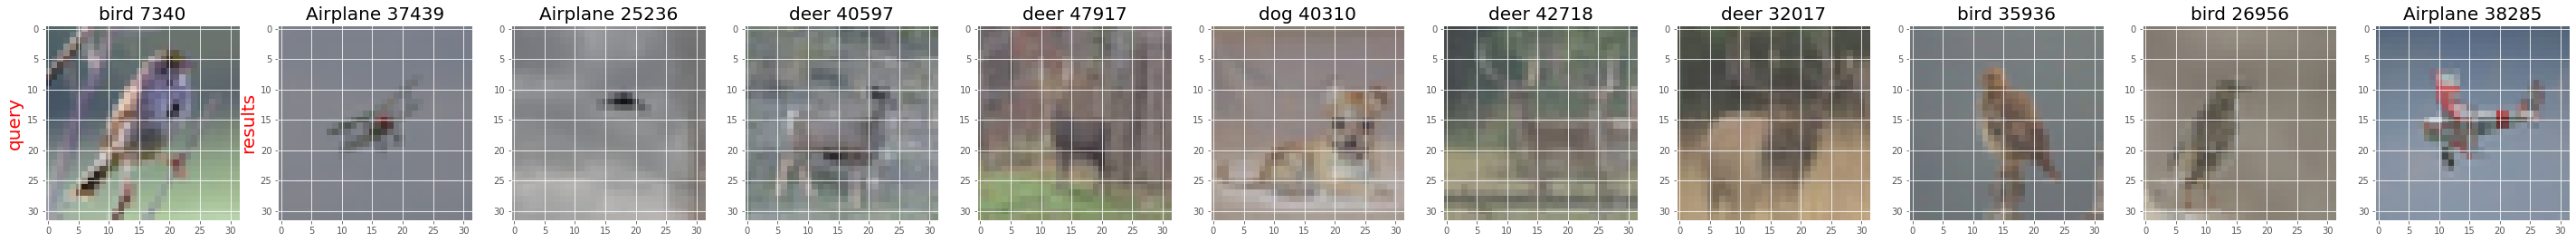

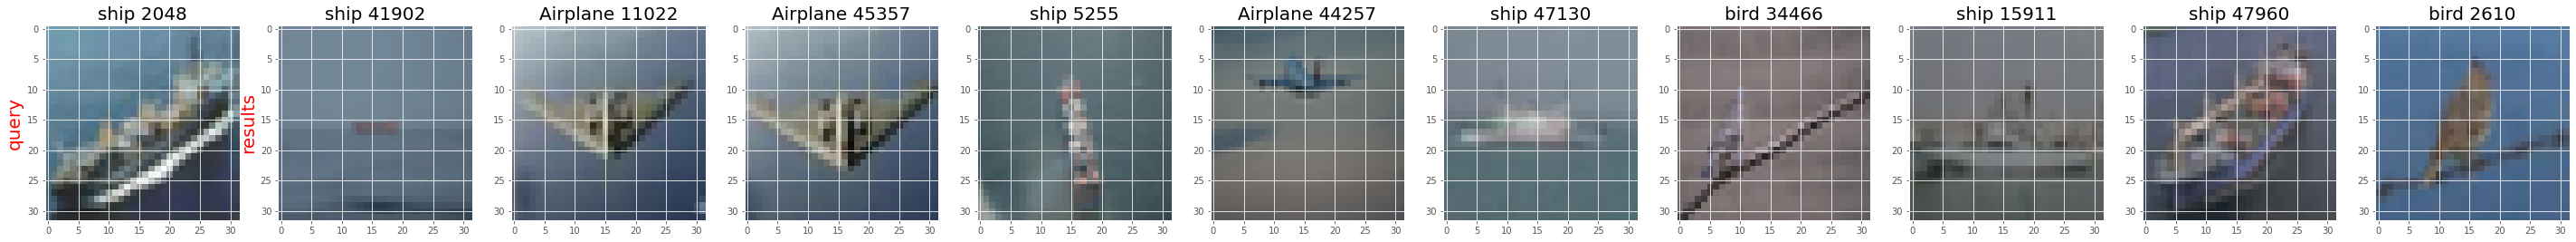

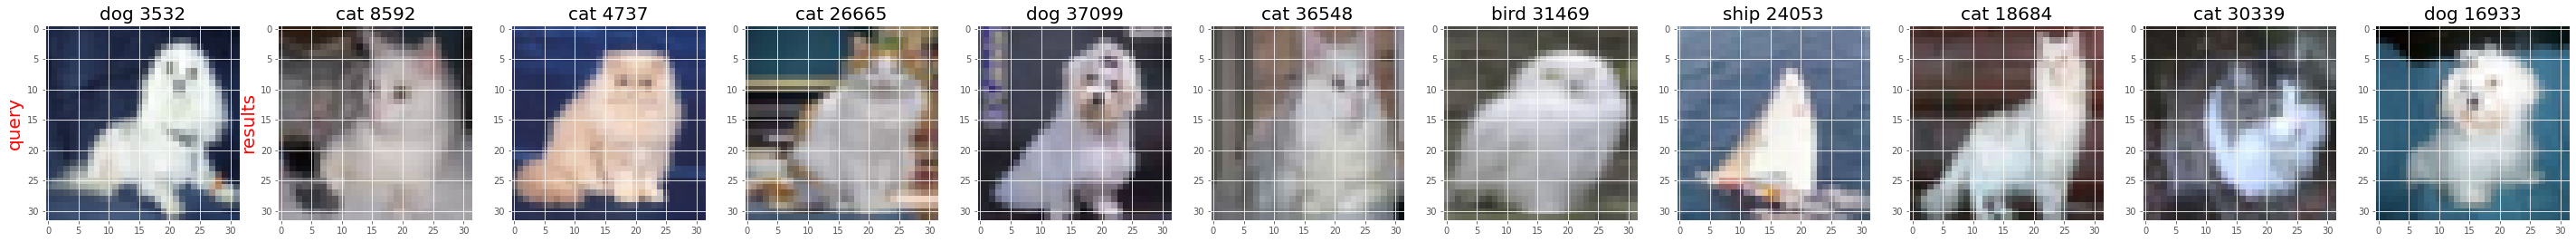

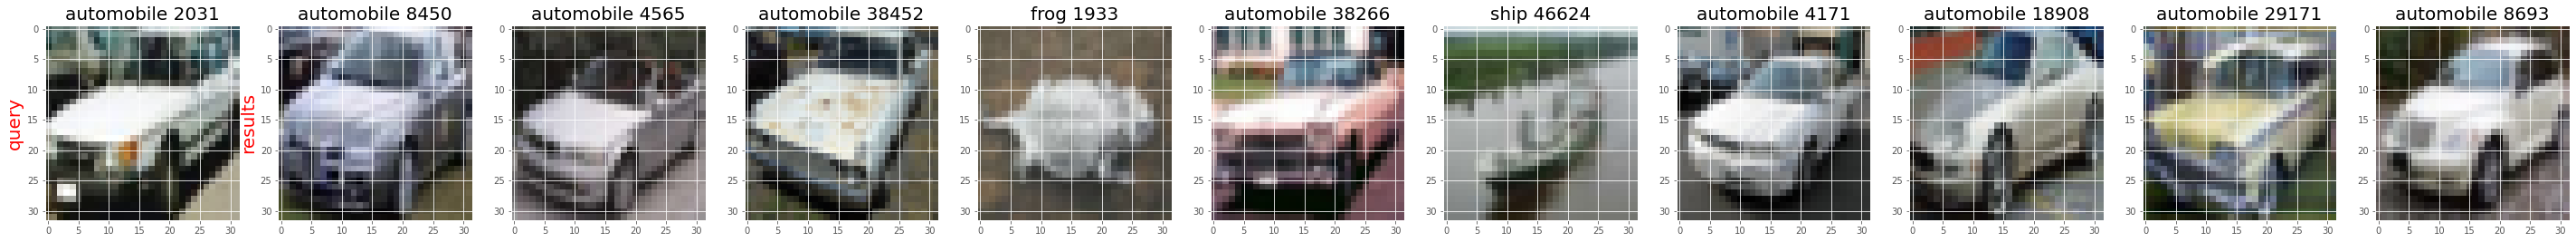

In [ ]:
for i in range(N_QUERIES):
  res = result_queries[i]
  _img = queries_imgs[i]
  N = len(res)

  fig=plt.figure(figsize=(50, 32))
  ax = fig.add_subplot(1, N+1, 1)
  plt.imshow(X_test[_img])
  ax.set_ylabel('query',fontsize=20, color='r')
  plt.title(f'{NAMES[y_test[_img][0]]} {_img}',fontsize=20)
  for i in range(N):
    _index = res[i]
    ax = fig.add_subplot(1, N+1, i+2)
    imgplot = plt.imshow(X_train[_index])
    ax.set_title(f'{NAMES[y_train[_index][0]]} {_index}',fontsize=20)
    if(i==0):
      ax.set_ylabel('results',fontsize=20, color='r')

#### Métrica

In [ ]:
def CountRelevantDocuments( results, y_label ):
  rd = 0
  for i in results:
    if( y_train[i] == y_label):
      rd+=1
  return rd

def _precision_at_k(Z_embedding, DataBase, k=10):
  N = Z_embedding.shape[0]
  total = 0
  for i in range(N):
    res = knn.kneighbors([Z_embedding_test[i]])[1][0]
    relevants = CountRelevantDocuments(res,y_test[i][0])
    total += (relevants/k)
  return total/N

In [ ]:
_precision_at_k(Z_embedding_test, DataBase)

0.2774999999999996

## AE/Clasificador -> Euclidian distance

#### Red

In [ ]:
def Red(dim_encod,shape):
  input_img = Input(shape=shape)
  chanDim = -1

  # Encoder Layers
  x = Conv2D(32, (3, 3), activation = LeakyReLU(alpha=0.2), padding="same")(input_img)
  x = Conv2D(32, (3, 3), activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = MaxPooling2D((2, 2), padding='same')(x)
  x = Dropout(0.2)(x)
  x = Conv2D(64, (3, 3), activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = Conv2D(64, (3, 3), activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = MaxPooling2D((2, 2), padding='same')(x)
  x = Dropout(0.2)(x)
  x = Flatten()(x)
  encoded = Dense(dim_encod, name="embedding")(x)


  # Decoder Layers
  flat_layer = Dense(4*4*128)(encoded)
  x = Reshape((4,4,128))(flat_layer)
  x = Conv2DTranspose(128, (3, 3), strides=2, activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = Conv2DTranspose(64, (3, 3), strides=2, activation = LeakyReLU(alpha=0.2), padding="same")(x)
  x = Conv2DTranspose(32, (3, 3), strides=2, activation = LeakyReLU(alpha=0.2), padding="same")(x)
  decoded = Conv2DTranspose(3, (3, 3), padding="same", activation = 'sigmoid', name="decoded")(x)

  # Clasificación
  y = Dropout(0.5)(encoded)
  out_class = Dense(10, activation="softmax", name="out_class")(y)


  # Models
  autoencoder = Model(input_img, [decoded,out_class])
  encoder = Model(input_img, encoded)
  autoencoder.compile(optimizer='adam', loss=['mse','categorical_crossentropy'],metrics=["accuracy"])
  return autoencoder, encoder
AE_3, E_3 = Red(DIM_ENCOD,INPUT_SHAPE)

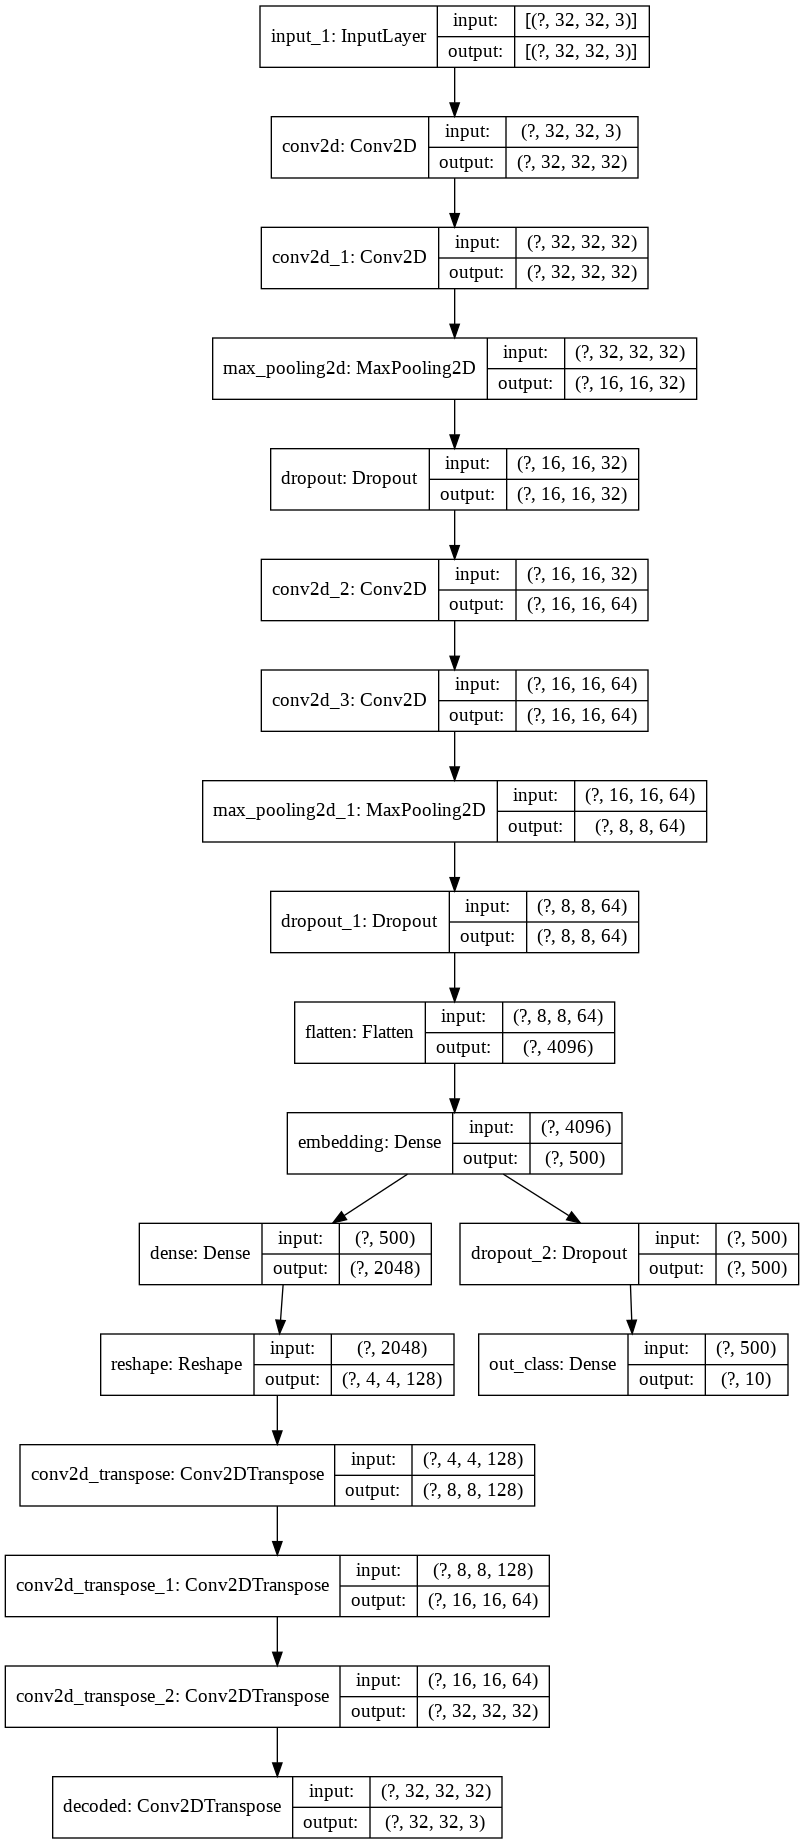

In [ ]:
plot_model(AE_3, show_shapes=True, show_layer_names=True)

In [ ]:
history_AE_3 = AE_3.fit(X_train, [X_train,y_train_HE], epochs=EPOCHS, batch_size=BATCH_SIZE, validation_split=0.2)

Epoch 1/15
313/313 [==============================] - 6s 21ms/step - loss: 1.5376 - decoded_loss: 0.0348 - out_class_loss: 1.5027 - decoded_accuracy: 0.5737 - out_class_accuracy: 0.4593 - val_loss: 1.1345 - val_decoded_loss: 0.0212 - val_out_class_loss: 1.1133 - val_decoded_accuracy: 0.6168 - val_out_class_accuracy: 0.6129
Epoch 2/15
313/313 [==============================] - 6s 19ms/step - loss: 1.0785 - decoded_loss: 0.0215 - out_class_loss: 1.0570 - decoded_accuracy: 0.6309 - out_class_accuracy: 0.6294 - val_loss: 0.9526 - val_decoded_loss: 0.0179 - val_out_class_loss: 0.9347 - val_decoded_accuracy: 0.6390 - val_out_class_accuracy: 0.6752
Epoch 3/15
313/313 [==============================] - 6s 19ms/step - loss: 0.9311 - decoded_loss: 0.0187 - out_class_loss: 0.9124 - decoded_accuracy: 0.6574 - out_class_accuracy: 0.6840 - val_loss: 0.8711 - val_decoded_loss: 0.0170 - val_out_class_loss: 0.8541 - val_decoded_accuracy: 0.6651 - val_out_class_accuracy: 0.7076
Epoch 4/15
313/313 [=====

#### Resultados

In [ ]:
X_decoded_train,_ = AE_3.predict(X_train)
X_decoded_test,_ = AE_3.predict(X_test)

Z_embedding_train = E_3.predict(X_train)
Z_embedding_test = E_3.predict(X_test)

Text(0.5, 1.0, 'Decoded image')

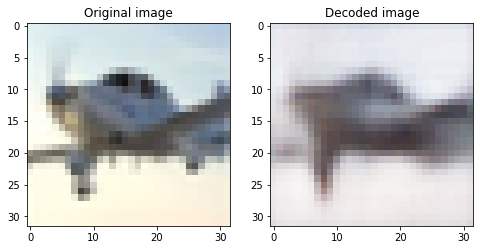

In [ ]:
fig=plt.figure(figsize=(8, 8))

_img = random.randint(0,X_test.shape[0])

ax = fig.add_subplot(1, 2, 1)
imgplot = plt.imshow(X_test[_img])
ax.set_title('Original image')

ax = fig.add_subplot(1, 2, 2)
imgplot = plt.imshow(X_decoded_test[_img])
ax.set_title('Decoded image')

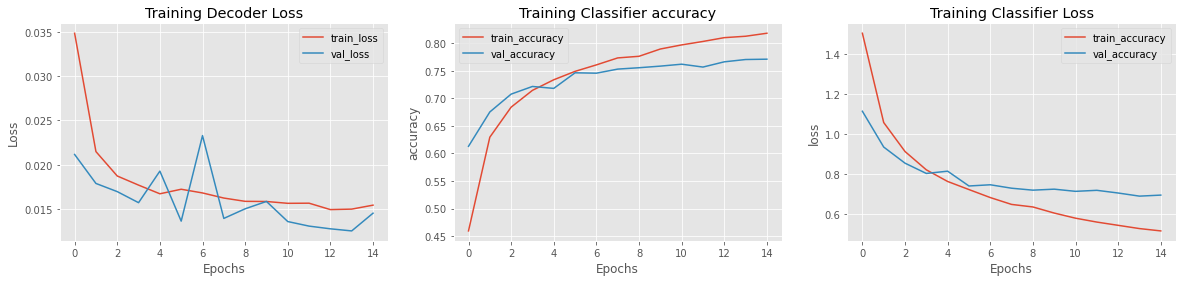

In [ ]:
N = np.arange(0, EPOCHS)
plt.style.use("ggplot")
fig = plt.figure(figsize=(20, 4))
ax = fig.add_subplot(1, 3, 1)
plt.plot(N, history_AE_3.history["decoded_loss"], label="train_loss")
plt.plot(N, history_AE_3.history["val_decoded_loss"], label="val_loss")
plt.title("Training Decoder Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(loc="upper right")

ax = fig.add_subplot(1, 3, 2)
plt.plot(N, history_AE_3.history["out_class_accuracy"], label="train_accuracy")
plt.plot(N, history_AE_3.history["val_out_class_accuracy"], label="val_accuracy")
plt.title("Training Classifier accuracy")
plt.xlabel("Epochs")
plt.ylabel("accuracy")
plt.legend(loc="upper left")

ax = fig.add_subplot(1, 3, 3)
plt.plot(N, history_AE_3.history["out_class_loss"], label="train_accuracy")
plt.plot(N, history_AE_3.history["val_out_class_loss"], label="val_accuracy")
plt.title("Training Classifier Loss")
plt.xlabel("Epochs")
plt.ylabel("loss")
plt.legend(loc="upper right")

#### Modelo

In [ ]:
indexes = list(range(0, X_train.shape[0]))
DataBase = {"indexes": indexes, "features": Z_embedding_train}

In [ ]:
def DBsearch(queryImg, index, maxResults=64):
	results = []
	for i in range(0, len(index["features"])):
		d = euclidean(queryImg, index["features"][i])
		results.append((d, i))
	results = sorted(results)[:maxResults]
	return results

def euclidean(a, b):
	return np.linalg.norm(a - b)

In [ ]:
N_QUERIES = 5
queries_imgs =  random.sample(range(Z_embedding_test.shape[0]), N_QUERIES)
result_queries = [ DBsearch(Z_embedding_test[i], DataBase, THRESHOLD) for i in queries_imgs]

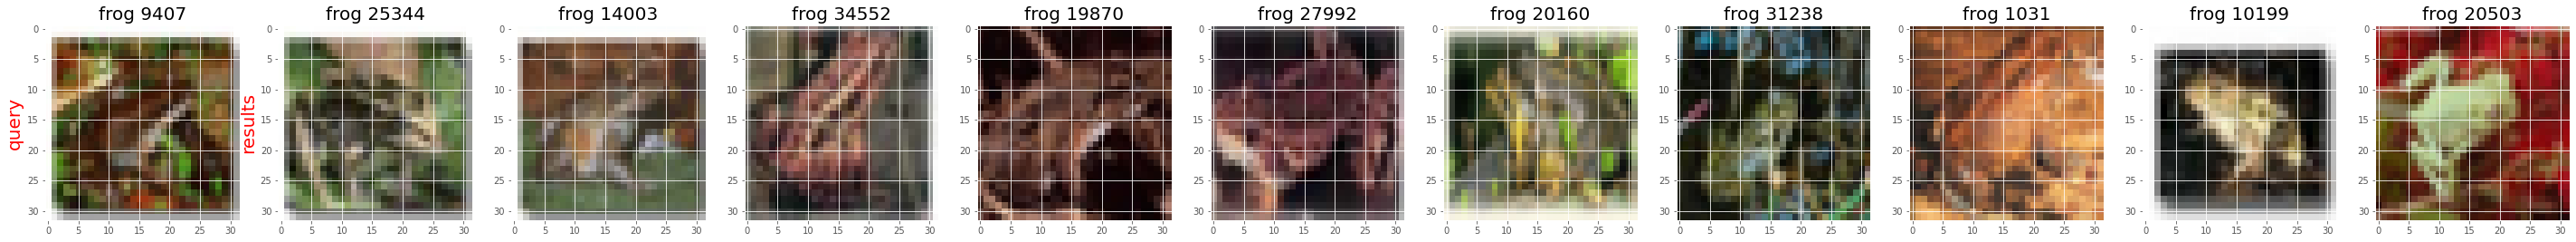

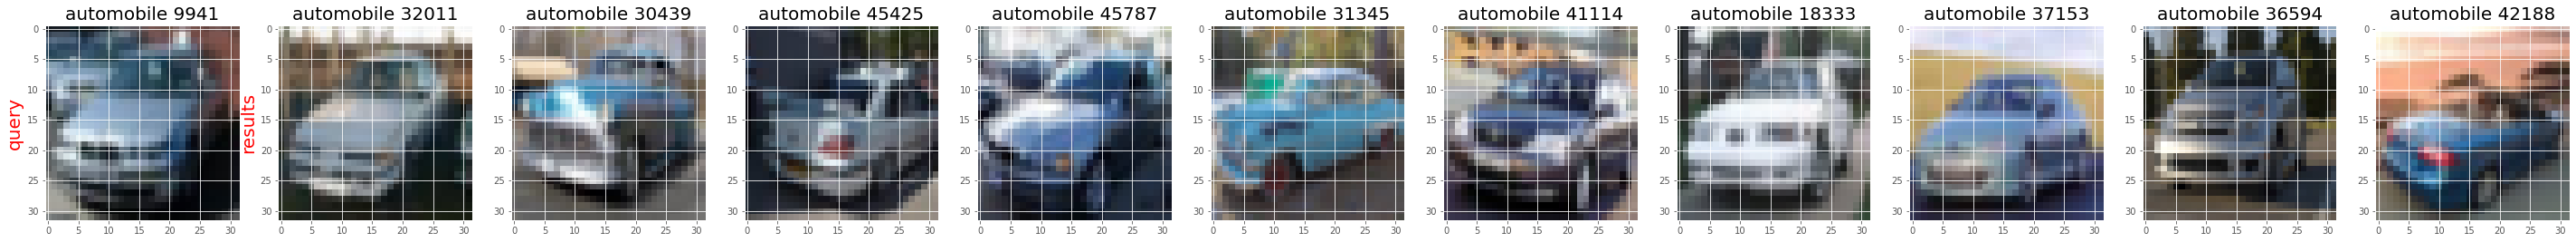

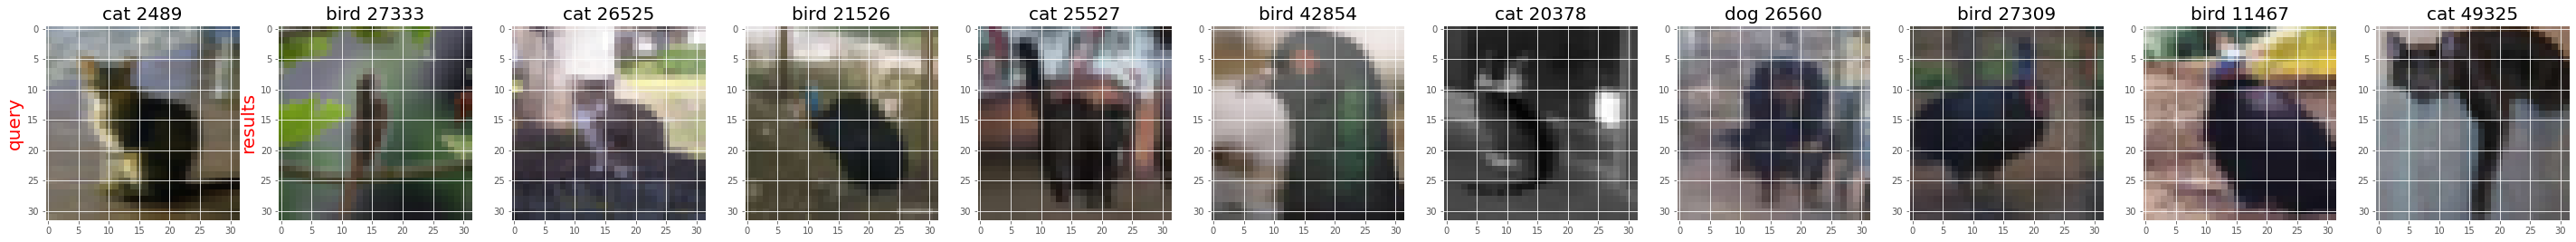

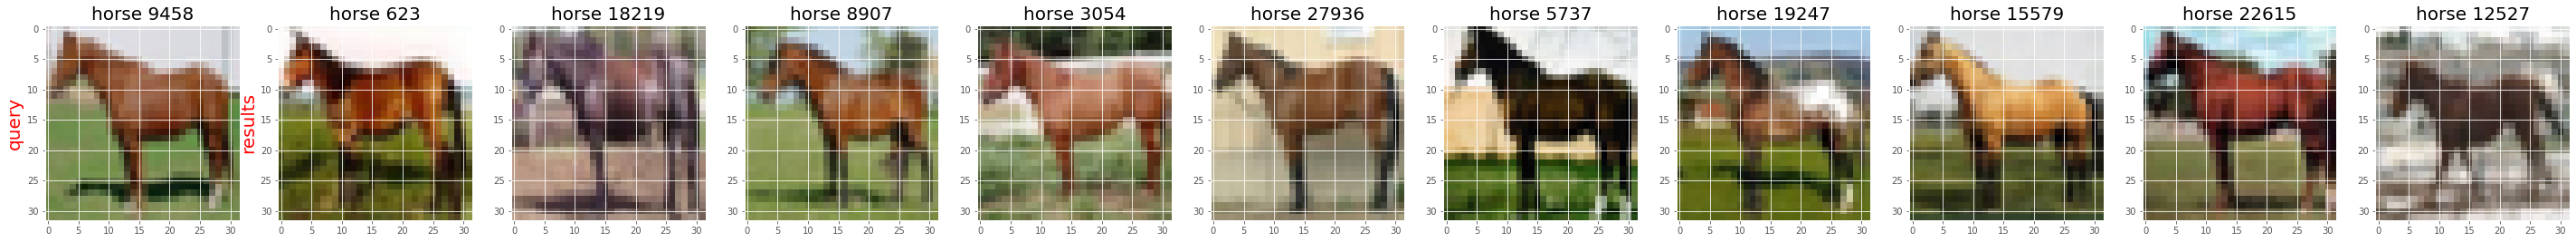

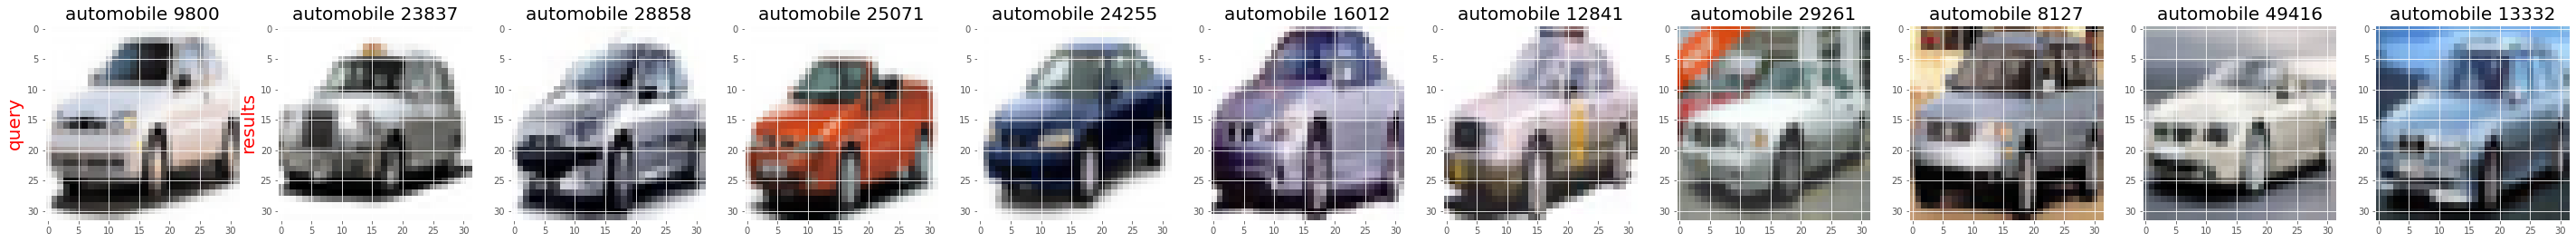

In [ ]:
for i in range(N_QUERIES):
  res = result_queries[i]
  _img = queries_imgs[i]
  N = len(res)

  fig=plt.figure(figsize=(50, 32))
  ax = fig.add_subplot(1, N+1, 1)
  plt.imshow(X_test[_img])
  ax.set_ylabel('query',fontsize=20, color='r')
  plt.title(f'{NAMES[y_test[_img][0]]} {_img}',fontsize=20)
  for i in range(N):
    _index = res[i][1]
    ax = fig.add_subplot(1, N+1, i+2)
    imgplot = plt.imshow(X_train[_index])
    ax.set_title(f'{NAMES[y_train[_index][0]]} {_index}',fontsize=20)
    if(i==0):
      ax.set_ylabel('results',fontsize=20, color='r')

#### Métrica

In [ ]:
def CountRelevantDocuments( results, y_label ):
  rd = 0
  for i in results:
    if( y_train[i[1]] == y_label):
      rd+=1
  return rd

def _precision_at_k(Z_embedding, DataBase, k=10):
  N = Z_embedding.shape[0]
  total = 0
  for i in range(N):
    res = DBsearch(Z_embedding[i], DataBase, k)
    relevants = CountRelevantDocuments(res,y_test[i][0])
    total += (relevants/k)
  return total/N

In [ ]:
_precision_at_k(Z_embedding_test, DataBase)

0.7291999999999997

#Cross-domain Image-Text

In [ ]:
import pickle 
from matplotlib import pyplot as plt 
from pydrive.auth import GoogleAuth
from pydrive.drive import GoogleDrive
from google.colab import auth
from oauth2client.client import GoogleCredentials
import random
from sklearn.model_selection import train_test_split


##Descargar y cargar la data

In [ ]:
auth.authenticate_user()
gauth = GoogleAuth()
gauth.credentials = GoogleCredentials.get_application_default()
drive = GoogleDrive(gauth)



In [ ]:
#downloaded = drive.CreateFile({'id':"1qDLVRGIJ-KhvBZshWFJCUwVuDSh8aNPp"})   
#downloaded.GetContentFile('imagenesFlickr8-128')
#downloaded = drive.CreateFile({'id':"1Zv6y-rXe06I8VF5DZjTVuGzW4sBWnKCS"})
#downloaded.GetContentFile('Flickr8k.token.txt')

arch =open('imagenesFlickr8-128','rb')
images = pickle.load(arch)
arch.close()

In [ ]:
imList = [(k, v) for k, v in images.items()]
#imList = list(images.values())
random.shuffle(imList)
#images = dict(imList)
imList = np.array(imList)
n_Images = len(imList)
training_data, test_data = train_test_split(imList, train_size=int(n_Images*0.8), test_size=n_Images-int(n_Images*0.8))

names_train = training_data[:,0]
training_CD = list(training_data[:,1])

names_test = test_data[:,0]
test_CD = list(test_data[:,1])

training_CD = np.array(training_CD,subok=True)
test_CD = np.array(test_CD,subok=True)
test_CD.shape
training_CD = training_CD.astype('float32') / 255.
test_CD = test_CD.astype('float32') / 255.

training_CD = training_CD.reshape(-1,128,128,3)
test_CD = test_CD.reshape(-1,128,128,3)

##Red


In [ ]:
def Red3(dim_encod,shape):
  input_img = Input(shape=shape)
  chanDim = -1

  # Encoder Layers
  x = Conv2D(32, (3, 3), strides=2, padding="same")(input_img)
  x = LeakyReLU(alpha=0.2)(x)
  x = BatchNormalization(axis=chanDim)(x)
  x = Conv2D(64, (3, 3), strides=2, padding="same")(x)
  x = LeakyReLU(alpha=0.2)(x)
  x = BatchNormalization(axis=chanDim)(x)
  x = Flatten()(x)
  encoded = Dense(dim_encod, name="embedding")(x)


  # Decoder Layers
  x = Dense(32*32*64)(encoded)
  x = Reshape((32,32,64))(x)
  x = Conv2DTranspose(64, (3, 3), strides=2, padding="same")(x)
  x = LeakyReLU(alpha=0.2)(x)
  x = BatchNormalization(axis=chanDim)(x)
  x = Conv2DTranspose(32, (3, 3), strides=2, padding="same")(x)
  x = LeakyReLU(alpha=0.2)(x)
  x = BatchNormalization(axis=chanDim)(x)
  x = Conv2DTranspose(3, (3, 3), padding="same")(x)
  decoded = Activation("sigmoid", name="decoded")(x)


  # Models
  autoencoder = Model(input_img, decoded)
  encoder = Model(input_img, encoded)
  autoencoder.compile(optimizer='adam', loss='mse')
  return autoencoder, encoder





In [ ]:
AE_CD, E_CD = Red3(1000,(128,128,3))
AE_CD.summary()

Model: "functional_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 128, 128, 3)]     0         
_________________________________________________________________
conv2d (Conv2D)              (None, 64, 64, 32)        896       
_________________________________________________________________
leaky_re_lu (LeakyReLU)      (None, 64, 64, 32)        0         
_________________________________________________________________
batch_normalization (BatchNo (None, 64, 64, 32)        128       
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 32, 32, 64)        18496     
_________________________________________________________________
leaky_re_lu_1 (LeakyReLU)    (None, 32, 32, 64)        0         
_________________________________________________________________
batch_normalization_1 (Batch (None, 32, 32, 64)       

In [ ]:
#Quizas con 20 epochs son sufici
history_AE_CD = AE_CD.fit(training_CD, training_CD, epochs=25, batch_size=128, validation_split=0.2)

Epoch 1/25
41/41 [==============================] - 18s 437ms/step - loss: 0.0555 - val_loss: 0.0615
Epoch 2/25
41/41 [==============================] - 17s 425ms/step - loss: 0.0357 - val_loss: 0.0628
Epoch 3/25
41/41 [==============================] - 18s 427ms/step - loss: 0.0297 - val_loss: 0.0618
Epoch 4/25
41/41 [==============================] - 18s 430ms/step - loss: 0.0260 - val_loss: 0.0563
Epoch 5/25
41/41 [==============================] - 18s 430ms/step - loss: 0.0234 - val_loss: 0.0560
Epoch 6/25
41/41 [==============================] - 18s 428ms/step - loss: 0.0212 - val_loss: 0.0523
Epoch 7/25
41/41 [==============================] - 18s 428ms/step - loss: 0.0192 - val_loss: 0.0490
Epoch 8/25
41/41 [==============================] - 18s 431ms/step - loss: 0.0179 - val_loss: 0.0411
Epoch 9/25
41/41 [==============================] - 18s 428ms/step - loss: 0.0168 - val_loss: 0.0378
Epoch 10/25
41/41 [==============================] - 18s 429ms/step - loss: 0.0155 - val_lo

##Predict

In [ ]:
X_decoded_train = AE_CD.predict(training_CD)
X_decoded_test = AE_CD.predict(test_CD)

Z_embedding_train = E_CD.predict(training_CD)
Z_embedding_test = E_CD.predict(test_CD)

Text(0.5, 1.0, 'Decoded image')

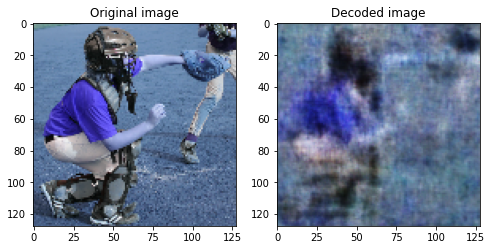

In [ ]:
fig=plt.figure(figsize=(8, 8))

_img = random.randint(0,test_CD.shape[0])

ax = fig.add_subplot(1, 2, 1)
imgplot = plt.imshow(test_CD[_img])
ax.set_title('Original image')

ax = fig.add_subplot(1, 2, 2)
imgplot = plt.imshow(X_decoded_test[_img])
ax.set_title('Decoded image')

In [ ]:
cap_dic = {}
captions = open('Flickr8k.token.txt','r')
for line in captions:
  try:
    name, caption = line.split('.jpg')
    name+='.jpg'
  except:
    print(line)
  caption = caption.strip().strip('#').strip('0').strip('1').strip('2').strip('3').strip('4').strip('\t')
  if name in names_train:
    try:
      cap_dic[name].append(caption)
    except:
      cap_dic[name] = [caption]
captions.close()

  

##DataBase

In [ ]:
def DataBase3():
  indexes = []
  features = []
  #captions = []
  for i in range(len(names_train)):
    indexes.append((i,cap_dic[names_train[i]]))
    features.append(Z_embedding_train[i])
    #captions.append(cap_dic[names_train[i]])
  return {"indexes":indexes, "features":features}
#indexes = list(range(0, training_CD.shape[0]))
#DataBase = {"indexes": indexes, "features": Z_embedding_train}

def real_cap(im_name):
  captions = open('Flickr8k.token.txt','r')
  cap =[]
  for line in captions:
    try:
      name, caption = line.split('.jpg')
      name+='.jpg'
      caption = caption.strip().strip('#').strip('0').strip('1').strip('2').strip('3').strip('4').strip('\t')
    except:
      print(line) 
    if name == im_name:
      cap.append(caption)
  

  captions.close()
  return cap

In [ ]:
DataBase_CD = DataBase3()


##Query

A brown dog is running along a beach .
A brown dog wearing a black collar running across the beach .
A dog walks on the sand near the water .
Brown dog running on the beach .
The large brown dog is running on the beach by the ocean .


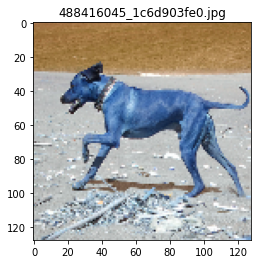

In [ ]:
_img = random.randint(0,test_CD.shape[0])
plt.imshow(test_CD[_img])
plt.title(names_test[_img])
capt = real_cap(names_test[_img])
for i in capt:
  print(i)

In [ ]:
res = DBsearch(Z_embedding_test[_img], DataBase_CD, THRESHOLD)


In [ ]:
N = len(res)

for i in range(N):
  _index = res[i][1]
  for j in DataBase_CD['indexes']:
    if j[0] == _index:
      for cap in j[1]:
        print(cap)
  print('------------------------')



A brown dog splashes in the water .
A dog leaps out of the water towards shore .
A dog near the shore of a body of water .
a tan dog jumping through the water towards the shore .
The brown dog is jumping out of the water
------------------------
A black and white dog walks along a sandy beach .
A dog walks along a beach .
A dog walks on the sand along the water .
A white dog running on the beach .
The dog is walking on the sand beside the ocean .
------------------------
A person skiing downhill in the snow .
A skier puffs up a cloud of snow .
A skier traveling downhill in deep snow .
Someone is skiing down a step snowy hill .
The skier is buried in the snow .
------------------------
A white dog is on a large rocky surface at a high elevation .
A white dog is walking on a rocky hillside .
A white dog is walking on top of a mountain .
White dog on mountainside turns to face something offstage , sky in background .
White dog standing on rock in front of blue sky
------------------------